# Examen Parcial 1 - Correccion

Juan Pablo Moran - 753760


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import KFold

df = pd.read_csv("e01_datos.csv")
print(df.shape)
df.head()

(183, 5)


,y,x1,x2,x3,grupo
0,13.643473,3.745401188473625,1.869147,6.363906,B
1,14.226813,9.50714306409916,6.743883,4.379466,A
2,15.312343,7.319939418114051,6.466175,5.648333,A
3,15.850062,5.986584841970366,3.012901,4.739714,A
4,15.477359,1.5601864044243652,1.443092,5.193992,B


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 183 entries, 0 to 182
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   y       183 non-null    float64
 1   x1      183 non-null    str    
 2   x2      181 non-null    float64
 3   x3      182 non-null    float64
 4   grupo   182 non-null    str    
dtypes: float64(3), str(2)
memory usage: 7.3 KB


In [3]:
print(df.isnull().sum())
print(df.duplicated().sum())

y        0
x1       0
x2       2
x3       1
grupo    1
dtype: int64
0


In [4]:
df.describe()

,y,x2,x3
count,183.000000,181.000000,182.000000
mean,14.053933,3.656675,5.054328
std,4.214684,2.596806,1.997665
min,4.000000,-2.194452,0.396158
25%,11.692237,1.603202,3.518048
50%,13.510425,3.463986,4.992027
75%,15.982460,5.689776,6.327197
max,42.000000,10.739239,11.157762


In [5]:
df["grupo"].value_counts(dropna=False)

grupo
A          73
B          60
C          42
a           1
 B          1
grupo_c     1
AA          1
c           1
NaN         1
b           1
D           1
Name: count, dtype: int64

Lo que encontre
- x1 sale como texto (str) y deberia ser numerica
- hay datos faltantes en x2 (2), x3 (1) y grupo (1)
- grupo tiene categorias mal escritas, no solo A, B y C
- y tiene un maximo de 42 cuando casi todo esta entre 11 y 16
- no hay filas duplicadas

## Limpieza de datos

Error 1: x1 es texto.

In [6]:
x1_num = pd.to_numeric(df["x1"], errors="coerce")
df[x1_num.isnull()]

,y,x1,x2,x3,grupo
12,16.398547,"4,271",6.869650,6.248240,A
88,18.813001,"7,654",6.087777,4.099869,B


Los valores 4,271 y 7,654 tienen coma decimal en vez de punto, por eso toda la columna se leyo como texto.

In [7]:
df["x1"] = df["x1"].str.replace(",", ".")
df["x1"] = pd.to_numeric(df["x1"])
df["x1"].dtype

dtype('float64')

Error 2: 
grupo tiene mayusculas y minusculas mezcladas, espacios.

In [8]:
grupo_min = df["grupo"].str.lower()
grupo_limpio = grupo_min.str.rstrip(" ")
print(grupo_limpio.unique())

<StringArray>
['b', 'a', 'c', ' b', 'grupo_c', 'aa', nan, 'd']
Length: 8, dtype: str


In [9]:
grupo_limpio[grupo_limpio == " b"] = "b"
grupo_limpio[grupo_limpio == "grupo_c"] = "c"
grupo_limpio[grupo_limpio == "aa"] = "a"
df["grupo"] = grupo_limpio
print(df["grupo"].unique())

<StringArray>
['b', 'a', 'c', nan, 'd']
Length: 5, dtype: str


- grupo_c se paso a c y aa a a porque claramente son esas categorias mal escritas
- d no es una categoria valida y no se sabe a cual corresponde, entonces esa fila se elimina

Error 3: datos faltantes. Se eliminan las filas con d y las que tienen NaN.

In [10]:
df = df[df["grupo"] != "d"]
df = df.dropna()
df = df.drop_duplicates()
df = df.reset_index(drop=True)
df.shape

(178, 5)

Se eliminaron 5 filas (183 -> 178): 1 con grupo d y 4 con faltantes (2 en x2, 1 en x3 y 1 en grupo). No hay forma de saber el valor real y son menos del 3% de los datos.

In [11]:
df.describe()

,y,x1,x2,x3
count,178.000000,178.000000,178.000000,178.000000
mean,14.130758,4.746166,3.685684,5.063340
std,4.233002,2.966370,2.599756,2.003016
min,4.000000,0.055221,-2.194452,0.396158
25%,11.715950,2.147813,1.606102,3.518048
50%,13.634059,4.641425,3.499782,4.992027
75%,16.030766,7.294564,5.717020,6.327197
max,42.000000,9.868869,10.739239,11.157762


Text(0, 0.5, 'y')

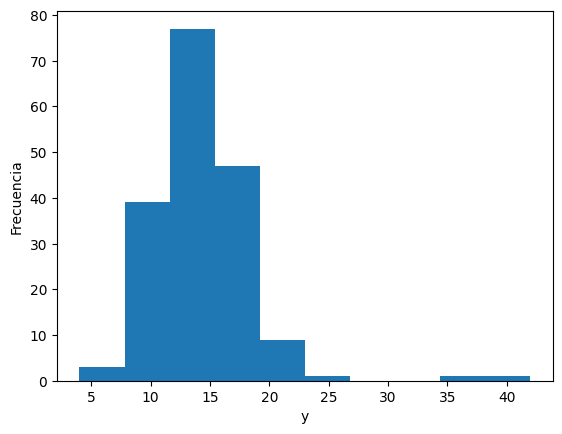

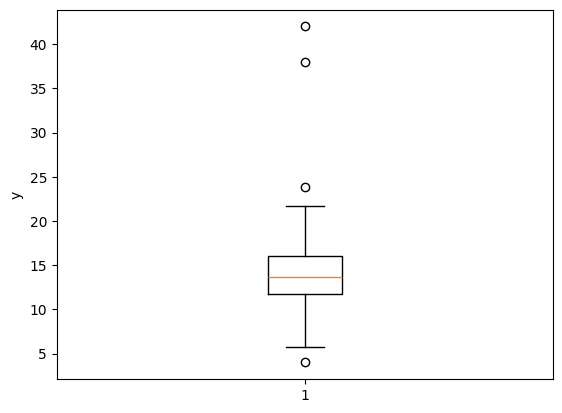

In [12]:
plt.figure()
plt.hist(df["y"])
plt.xlabel("y")
plt.ylabel("Frecuencia")

plt.figure()
plt.boxplot(df["y"])
plt.ylabel("y")

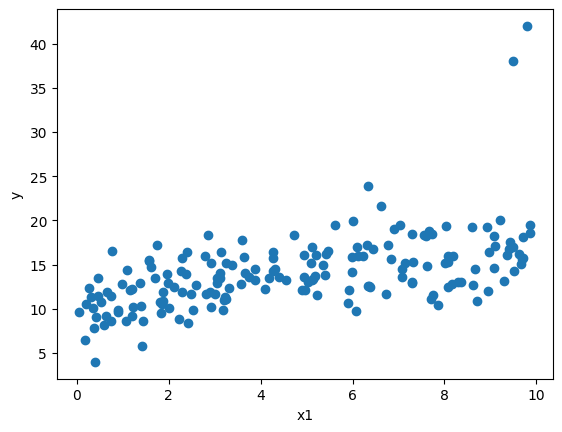

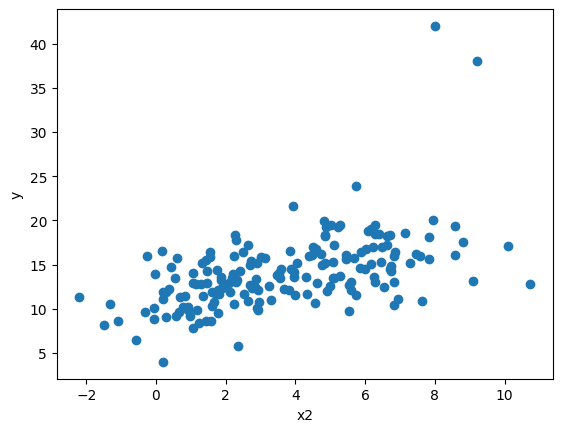

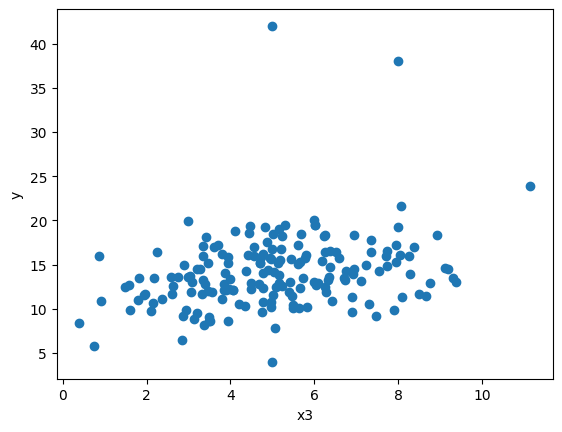

In [13]:
for col in ["x1", "x2", "x3"]:
    plt.figure()
    plt.scatter(df[col], df["y"])
    plt.xlabel(col)
    plt.ylabel("y")

In [14]:
df[["y", "x1", "x2", "x3"]].corr()

,y,x1,x2,x3
y,1.000000,0.540937,0.527634,0.291556
x1,0.540937,1.000000,0.881887,-0.024775
x2,0.527634,0.881887,1.000000,-0.025579
x3,0.291556,-0.024775,-0.025579,1.000000


- todavia hay dos valores de y muy altos (38 y 42), se revisan despues con los residuos
- y sube con x1 y x2, con x3 la relacion es mas debil
- x1 y x2 tienen correlacion de 0.88, casi miden lo mismo (posible colinealidad)

Como grupo es cualitativa se crean variables indicadoras. Se usan 2 (k - 1) y a queda como base.

In [15]:
df["grupoB"] = (df["grupo"] == "b").astype(int)
df["grupoC"] = (df["grupo"] == "c").astype(int)
df.head()

,y,x1,x2,x3,grupo,grupoB,grupoC
0,13.643473,3.745401,1.869147,6.363906,b,1,0
1,14.226813,9.507143,6.743883,4.379466,a,0,0
2,15.312343,7.319939,6.466175,5.648333,a,0,0
3,15.850062,5.986585,3.012901,4.739714,a,0,0
4,15.477359,1.560186,1.443092,5.193992,b,1,0


## Modelo lineal multiple

In [16]:
columnas = ["x1", "x2", "x3", "grupoB", "grupoC"]
X = df[columnas]
Y = df["y"]

lr = LinearRegression()
lr.fit(X, Y)
print(lr.intercept_)
print(lr.coef_)
print(lr.score(X, Y))

6.456902214627415
[ 0.63754897  0.2333242   0.6652717   2.69734601 -2.25772832]
0.5935012316808936


In [17]:
y_pred = lr.predict(X)
residuos = Y - y_pred

X_mat = np.hstack([np.ones([len(X), 1]), X.values])
n, p = X_mat.shape
rse = np.sqrt(np.sum(residuos**2) / (n - p))
var_beta = np.linalg.inv(X_mat.T @ X_mat) * rse**2
std_beta = np.sqrt(var_beta.diagonal())
beta = np.hstack([lr.intercept_, lr.coef_])

pd.DataFrame({"coef": beta, "SE": std_beta, "t": beta / std_beta}, index=["intercepto"] + columnas)

,coef,SE,t
intercepto,6.456902,0.691132,9.342495
x1,0.637549,0.148821,4.284006
x2,0.233324,0.169819,1.373959
x3,0.665272,0.102993,6.459415
grupoB,2.697346,0.475874,5.668192
grupoC,-2.257728,0.533949,-4.228360


- R2 = 0.59
- con |t| > 1.97 son significativos x1, x3, grupoB y grupoC; x2 no (t = 1.37), probablemente porque se parece mucho a x1

## 6 errores comunes

1. No linealidad

Text(0, 0.5, 'Residuos')

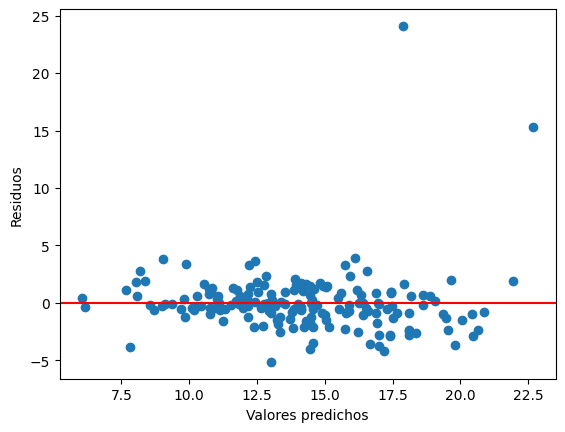

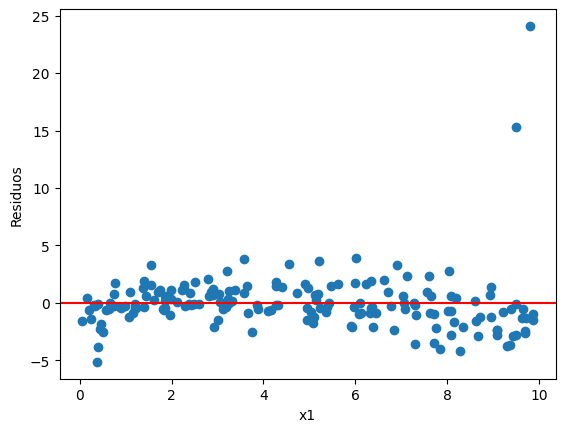

In [18]:
plt.figure()
plt.scatter(y_pred, residuos)
plt.axhline(0, color="red")
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")

plt.figure()
plt.scatter(df["x1"], residuos)
plt.axhline(0, color="red")
plt.xlabel("x1")
plt.ylabel("Residuos")

Hay dos residuos muy grandes. Contra x1 se alcanza a ver una curva, se revisa otra vez sin los atipicos.

2. Correlacion en errores

Text(0, 0.5, 'Residuos')

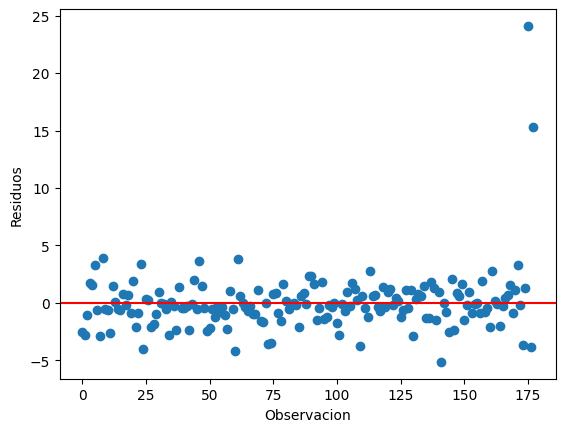

In [19]:
plt.figure()
plt.scatter(range(len(residuos)), residuos)
plt.axhline(0, color="red")
plt.xlabel("Observacion")
plt.ylabel("Residuos")

No se ve patron en el orden de los datos, no hay correlacion en errores.

3. Varianza no constante

Se revisa con la grafica de residuos contra valores predichos (la de no linealidad): no se ve forma de embudo, la dispersion es parecida en todo el rango. No hay varianza no constante.

4. Valores atipicos

,y,x1,x2,x3,grupo,grupoB,grupoC
175,42.0,9.8,8.0,5.0,a,0,0
177,38.0,9.5,9.2,8.0,b,1,0


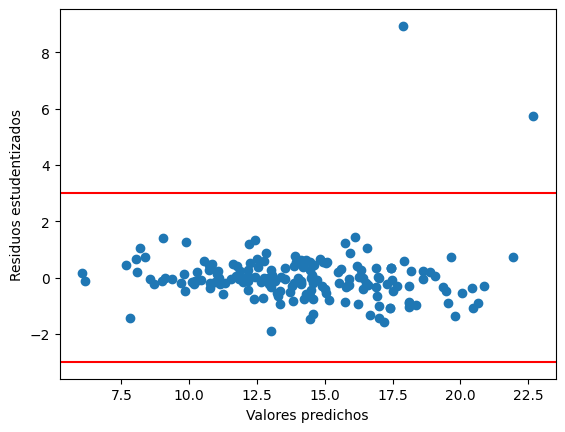

In [20]:
H = X_mat @ np.linalg.inv(X_mat.T @ X_mat) @ X_mat.T
leverage = np.diag(H)
resid_student = residuos / (rse * np.sqrt(1 - leverage))

plt.figure()
plt.scatter(y_pred, resid_student)
plt.axhline(3, color="red")
plt.axhline(-3, color="red")
plt.xlabel("Valores predichos")
plt.ylabel("Residuos estudentizados")

df[np.abs(resid_student) > 3]

Hay 2 outliers: y = 42 y y = 38. Tienen valores redondos que no se parecen al resto del archivo, parecen otro error deliberado.

5. Puntos palanca

0.03932584269662921
45


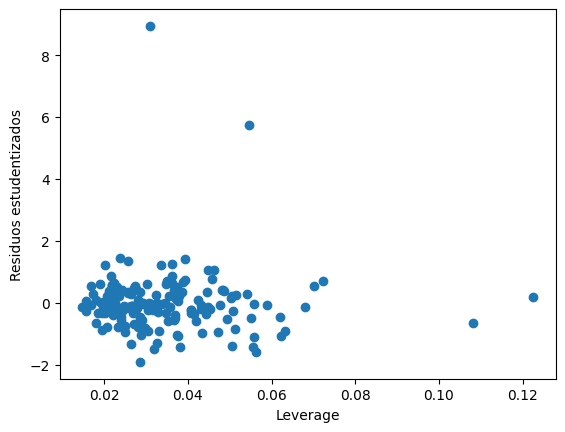

In [21]:
plt.figure()
plt.scatter(leverage, resid_student)
plt.xlabel("Leverage")
plt.ylabel("Residuos estudentizados")

print((p + 1) / n)
print(len(df[leverage > (p + 1) / n]))

Hay 45 puntos con leverage mayor a (p+1)/n, pero sus residuos son normales entonces no se quitan. Los unicos que se salen de todo son los dos outliers.

6. Colinealidad

In [22]:
for col in ["x1", "x2", "x3"]:
    otras = ["x1", "x2", "x3", "grupoB", "grupoC"]
    otras.remove(col)
    lr_aux = LinearRegression()
    lr_aux.fit(df[otras], df[col])
    print(col, 1 / (1 - lr_aux.score(df[otras], df[col])))

x1 4.602034360750604
x2 4.602665146648476
x3 1.0049698005715966


VIF de 4.6 en x1 y x2, colinealidad moderada. Por eso x2 no sale significativa.

Se eliminan los 2 outliers porque tienen residuo estudentizado mayor a 3 y sus valores redondos parecen capturados mal.

In [23]:
df2 = df[np.abs(resid_student) <= 3]
df2 = df2.reset_index(drop=True)
print(df2.shape)

X2 = df2[columnas]
Y2 = df2["y"]
lr2 = LinearRegression()
lr2.fit(X2, Y2)
print(lr2.intercept_)
print(lr2.coef_)
print(lr2.score(X2, Y2))

(176, 7)
7.126575524779457
[ 0.62651837  0.07175508  0.58748831  2.81205939 -1.83979667]
0.7653369749601319


Text(0, 0.5, 'Residuos')

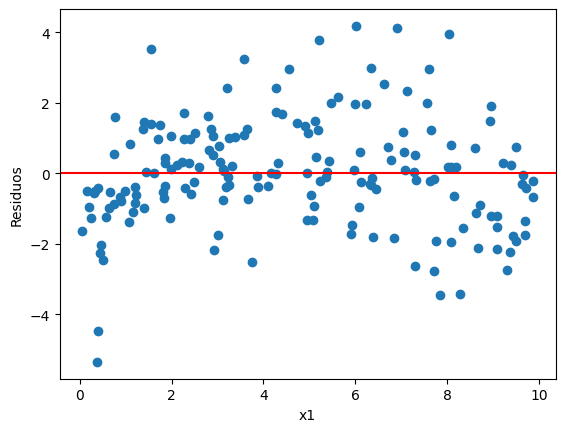

In [24]:
residuos2 = Y2 - lr2.predict(X2)
plt.figure()
plt.scatter(df2["x1"], residuos2)
plt.axhline(0, color="red")
plt.xlabel("x1")
plt.ylabel("Residuos")

Sin los outliers el R2 sube a 0.77. Contra x1 los residuos hacen una curva, entonces conviene agregar x1^2.

## Mejora y comparacion de modelos con validacion cruzada
Se comparan 3 modelos con K-Fold de 10 y MSE:
- M1: el modelo lineal
- M2: agregando x1^2
- M3: con x1^2 y sin x2

In [25]:
df2["x1_2"] = df2["x1"]**2

modelos = {
    "M1": ["x1", "x2", "x3", "grupoB", "grupoC"],
    "M2": ["x1", "x1_2", "x2", "x3", "grupoB", "grupoC"],
    "M3": ["x1", "x1_2", "x3", "grupoB", "grupoC"],
}

kf = KFold(n_splits=10)
filas = []
for nombre, cols in modelos.items():
    X_m = df2[cols]
    mse_lista = []
    for train_index, test_index in kf.split(X_m):
        X_train, X_test = X_m.iloc[train_index], X_m.iloc[test_index]
        Y_train, Y_test = Y2.iloc[train_index], Y2.iloc[test_index]
        lr = LinearRegression()
        lr.fit(X_train, Y_train)
        y_pred = lr.predict(X_test)
        mse_lista.append(np.sum((Y_test - y_pred)**2) / len(Y_test))
    filas.append({"Modelo": nombre, "MSE medio": np.mean(mse_lista), "Desv MSE": np.std(mse_lista)})

pd.DataFrame(filas)

,Modelo,MSE medio,Desv MSE
0,M1,2.561767,0.710870
1,M2,2.175197,0.625049
2,M3,2.162970,0.629697


M2 y M3 bajan el error de 2.56 a 2.16-2.18. M3 es el mejor y tiene una variable menos.

Tambien se prueba Ridge y Lasso sobre M2 (estandarizando con la media y desviacion de cada fold de entrenamiento).

In [26]:
X_m = df2[modelos["M2"]]
alphas = [0.001, 0.01, 0.1, 1, 10]
filas_pen = []
for a in alphas:
    mse_ridge = []
    mse_lasso = []
    for train_index, test_index in kf.split(X_m):
        X_train, X_test = X_m.iloc[train_index], X_m.iloc[test_index]
        Y_train, Y_test = Y2.iloc[train_index], Y2.iloc[test_index]
        media = X_train.mean()
        desv = X_train.std()
        X_train = (X_train - media) / desv
        X_test = (X_test - media) / desv

        ridge = Ridge(alpha=a)
        ridge.fit(X_train, Y_train)
        mse_ridge.append(np.sum((Y_test - ridge.predict(X_test))**2) / len(Y_test))

        lasso = Lasso(alpha=a)
        lasso.fit(X_train, Y_train)
        mse_lasso.append(np.sum((Y_test - lasso.predict(X_test))**2) / len(Y_test))
    filas_pen.append({"alpha": a, "MSE Ridge": np.mean(mse_ridge), "MSE Lasso": np.mean(mse_lasso)})

pd.DataFrame(filas_pen)

,alpha,MSE Ridge,MSE Lasso
0,0.001,2.175195,2.174731
1,0.010,2.175178,2.182417
2,0.100,2.175320,2.595080
3,1.000,2.197107,6.405123
4,10.000,2.511297,10.420050


Con alpha chico dan casi lo mismo que sin penalizar y con alpha grande empeoran. Penalizar no ayuda aqui.

5.624174031094711
['x1', 'x1_2', 'x3', 'grupoB', 'grupoC']
[ 1.51879238 -0.08516515  0.61943436  2.83281791 -1.78388232]
0.8023349484943595


Text(0, 0.5, 'Residuos')

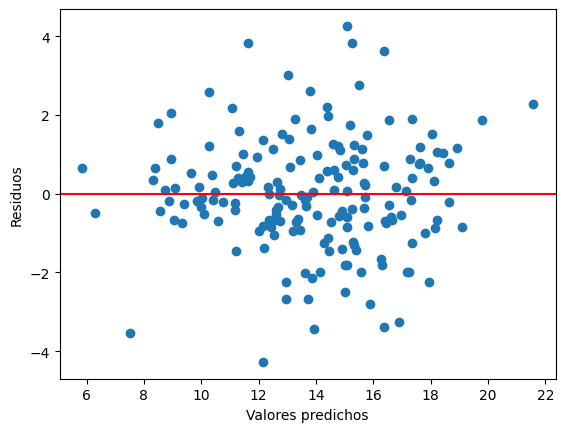

In [27]:
cols_final = modelos["M3"]
lr_final = LinearRegression()
lr_final.fit(df2[cols_final], Y2)
print(lr_final.intercept_)
print(cols_final)
print(lr_final.coef_)
print(lr_final.score(df2[cols_final], Y2))

plt.figure()
plt.scatter(lr_final.predict(df2[cols_final]), Y2 - lr_final.predict(df2[cols_final]))
plt.axhline(0, color="red")
plt.xlabel("Valores predichos")
plt.ylabel("Residuos")

## Correccion
Cual fue el error? No pude limpiar los datos (x1 como texto, grupo mal escrito y faltantes) y por eso no pude hacer el modelo ni lo demas.

Por que aparecio? No me acordaba de los comandos de limpieza del Lab R3 y no me di cuenta que lo que salia en info() eran los errores del archivo.

Como puedo evitar que pase? Siempre revisar con info(), describe(), isnull().sum() y value_counts() antes de hacer el modelo y tener anotado como se limpie.